<a href="https://colab.research.google.com/github/Aryan2206-jpg/creditcardfrauddetection/blob/main/creditcardfrauddetection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import zipfile
import matplotlib.pyplot as plt
import seaborn as sns

# New Section

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

In [ ]:
csv_path = 'creditcard.csv'
try:
    df = pd.read_csv("creditcard.csv")
    print("Dataset loaded successfully!")
    print(df.head())
except FileNotFoundError:
    print(f"Error: '{"creditcard.csv"}' not found. Please upload the file or check the path.")

Dataset loaded successfully!
   Applicant_ID  Age  Annual_Income  Employment_Years  Credit_Score  \
0             1   59         153267                28           818   
1             2   49         232745                 0           436   
2             3   35         974945                19           797   
3             4   63         307164                29           776   
4             5   28         685626                 6           893   

   Loan_Amount  Loan_Term_Months  Existing_Loans_Count  Debt_to_Income_Ratio  \
0       196649                12                     2                  0.68   
1       175354                60                     0                  0.23   
2       662297                48                     3                  0.54   
3       831725                48                     0                  0.56   
4       498625                60                     3                  0.66   

   Late_Payments_Last_2Yrs Credit_Risk  
0                     

In [ ]:
print("Dataset Shape:", df.shape)
print(df.head())


Dataset Shape: (500, 11)
   Applicant_ID  Age  Annual_Income  Employment_Years  Credit_Score  \
0             1   59         153267                28           818   
1             2   49         232745                 0           436   
2             3   35         974945                19           797   
3             4   63         307164                29           776   
4             5   28         685626                 6           893   

   Loan_Amount  Loan_Term_Months  Existing_Loans_Count  Debt_to_Income_Ratio  \
0       196649                12                     2                  0.68   
1       175354                60                     0                  0.23   
2       662297                48                     3                  0.54   
3       831725                48                     0                  0.56   
4       498625                60                     3                  0.66   

   Late_Payments_Last_2Yrs Credit_Risk  
0                        0

In [ ]:
print("\nMissing Values:")
print(df.isnull().sum())



Missing Values:
Applicant_ID               0
Age                        0
Annual_Income              0
Employment_Years           0
Credit_Score               0
Loan_Amount                0
Loan_Term_Months           0
Existing_Loans_Count       0
Debt_to_Income_Ratio       0
Late_Payments_Last_2Yrs    0
Credit_Risk                0
dtype: int64


In [ ]:
X = df.drop("Credit_Risk", axis=1)
y = df["Credit_Risk"]

In [ ]:
df_clean = df.dropna()

X_clean = df_clean.drop("Credit_Risk", axis=1)
y_clean = df_clean["Credit_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X_clean,
    y_clean,
    test_size=0.2,
    random_state=42,
    stratify=y_clean
)

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)



In [ ]:
model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
y_pred = model.predict(X_test)


In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro', zero_division=0)
recall = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

In [ ]:
print("\nMODEL PERFORMANCE")
print("-------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)


MODEL PERFORMANCE
-------------------------
Accuracy : 0.79
Precision: 0.6924603174603173
Recall   : 0.8455988455988456
F1 Score : 0.7398205659075224


In [ ]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

        High       0.91      0.81      0.86        63
         Low       0.50      1.00      0.67         4
      Medium       0.67      0.73      0.70        33

    accuracy                           0.79       100
   macro avg       0.69      0.85      0.74       100
weighted avg       0.81      0.79      0.80       100



In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)




Confusion Matrix:
[[51  0 12]
 [ 0  4  0]
 [ 5  4 24]]


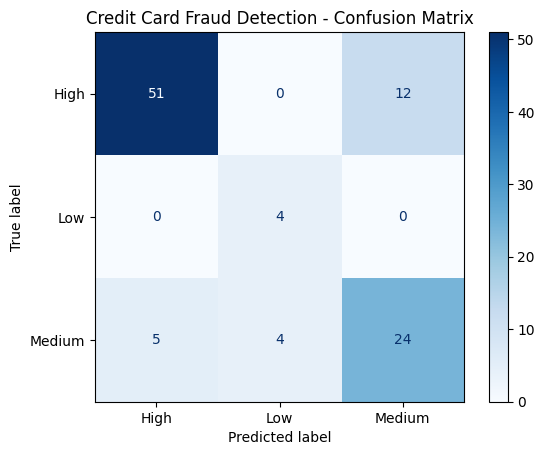

In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["High", "Low", "Medium"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Credit Card Fraud Detection - Confusion Matrix")
plt.show()

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

scores = [
    accuracy_score(y_test, y_pred),
    precision_score(y_test, y_pred, zero_division=0),
    recall_score(y_test, y_pred, zero_division=0),
    f1_score(y_test, y_pred, zero_division=0)
]


In [ ]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    metrics,
    scores,
    color=["blue", "green", "orange", "red"]
)

In [ ]:
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{height:.2f}",
        ha="center"
    )


In [ ]:
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Machine Learning Model Performance")

plt.ylim(0, 1.1)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

In [ ]:
import joblib

joblib.dump(model, "fraud_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(X.columns.tolist(), "features.pkl")

In [ ]:
from fastapi import FastAPI
from pydantic import BaseModel
import pandas as pd
import joblib

app = FastAPI(title="Credit Card Fraud Detection")

model = joblib.load("fraud_model.pkl")
scaler = joblib.load("scaler.pkl")
features = joblib.load("features.pkl")

class Transaction(BaseModel):
    values: list[float]

@app.post("/predict")
def predict(data: Transaction):

    if len(data.values) != len(features):
        return {"error": "Incorrect number of features"}

    df = pd.DataFrame([data.values], columns=features)
    scaled = scaler.transform(df)

    prediction = model.predict(scaled)[0]

    return {
        "prediction": int(prediction),
        "result": "Fraud" if prediction == 1 else "Normal"
    }